# PAS labels on latest version + top view

This notebook now auto-selects the **latest** PAS label file in the sequence folder (highest `V*`, typically `V2`) and overlays labels on **`VIDEO_USS_TOPVIEW.jpg`**.

**Coordinates:** CSV geometry (`PolygonX`/`PolygonY`, `xmin`…`ymax`) is in the measurement/world frame. The top-view overlay uses a bbox-fit mapping, so it is a quick visualization, not a calibrated projection.

- **Top-view:** polygons + dashed CSV boxes.
- **Front/Rear:** shown as camera references.
- **Bottom-right:** measurement-space polygons.

Use `.venv` as the notebook kernel, then re-run all cells.


In [13]:
from __future__ import annotations

import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon as MplPolygon
from matplotlib import image as mpimg

# Folder for one sequence (change to another under auto-labeler/data/...)
SEQUENCE_DIR = Path("data/106041_20190311_LB_XO2617_012_165618").resolve()

assert SEQUENCE_DIR.is_dir(), SEQUENCE_DIR

In [14]:
def find_latest_label_csv(seq_dir: Path) -> Path:
    paths = sorted(seq_dir.glob("*_PAS_m_label_V*.csv"))
    if not paths:
        raise FileNotFoundError(f"No *_PAS_m_label_V*.csv in {seq_dir}")

    def version_num(path: Path) -> int:
        token = path.stem.split("_PAS_m_label_V")[-1]
        return int(token) if token.isdigit() else -1

    return max(paths, key=version_num)


def load_pas_rows(csv_path: Path) -> tuple[list[str], list[dict[str, str]]]:
    with csv_path.open(newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        fieldnames = [h.strip() if h else h for h in (reader.fieldnames or [])]
        rows = []
        for raw in reader:
            row = {(k.strip() if k else k): (v.strip() if isinstance(v, str) else v) for k, v in raw.items()}
            rows.append(row)
    return fieldnames, rows


def parse_polygon_xy(row: dict[str, str]) -> tuple[np.ndarray, np.ndarray]:
    xs = np.array([float(x) for x in row["PolygonX"].split(",")], dtype=np.float64)
    ys = np.array([float(y) for y in row["PolygonY"].split(",")], dtype=np.float64)
    if len(xs) != len(ys):
        raise ValueError("PolygonX/Y length mismatch")
    return xs, ys


def class_label(row: dict[str, str]) -> str:
    for k in row:
        if k and k.startswith("class ("):
            return row[k]
    raise KeyError("class column not found")


label_path = find_latest_label_csv(SEQUENCE_DIR)
_, rows = load_pas_rows(label_path)
print("Using latest label file:", label_path.name)
print("rows:", len(rows))
for i, r in enumerate(rows):
    print(i, class_label(r), r.get("Which object", ""), "#", r.get("#", ""))

Using latest label file: 20190311_LB_XO2617_012_165618_PAS_m_label_V2.csv
rows: 2
0 3 hedge # 1
1 0 empty # 2


In [15]:
stem = label_path.name.split("_PAS_m_label_")[0]

front = SEQUENCE_DIR / f"{stem}_Front.avi.jpg"
rear = SEQUENCE_DIR / f"{stem}_Rear.avi.jpg"
top_view = SEQUENCE_DIR / "VIDEO_USS_TOPVIEW.jpg"

for path in (front, rear, top_view):
    print(path.name, "exists" if path.is_file() else "MISSING")


20190311_LB_XO2617_012_165618_Front.avi.jpg exists
20190311_LB_XO2617_012_165618_Rear.avi.jpg exists
VIDEO_USS_TOPVIEW.jpg exists


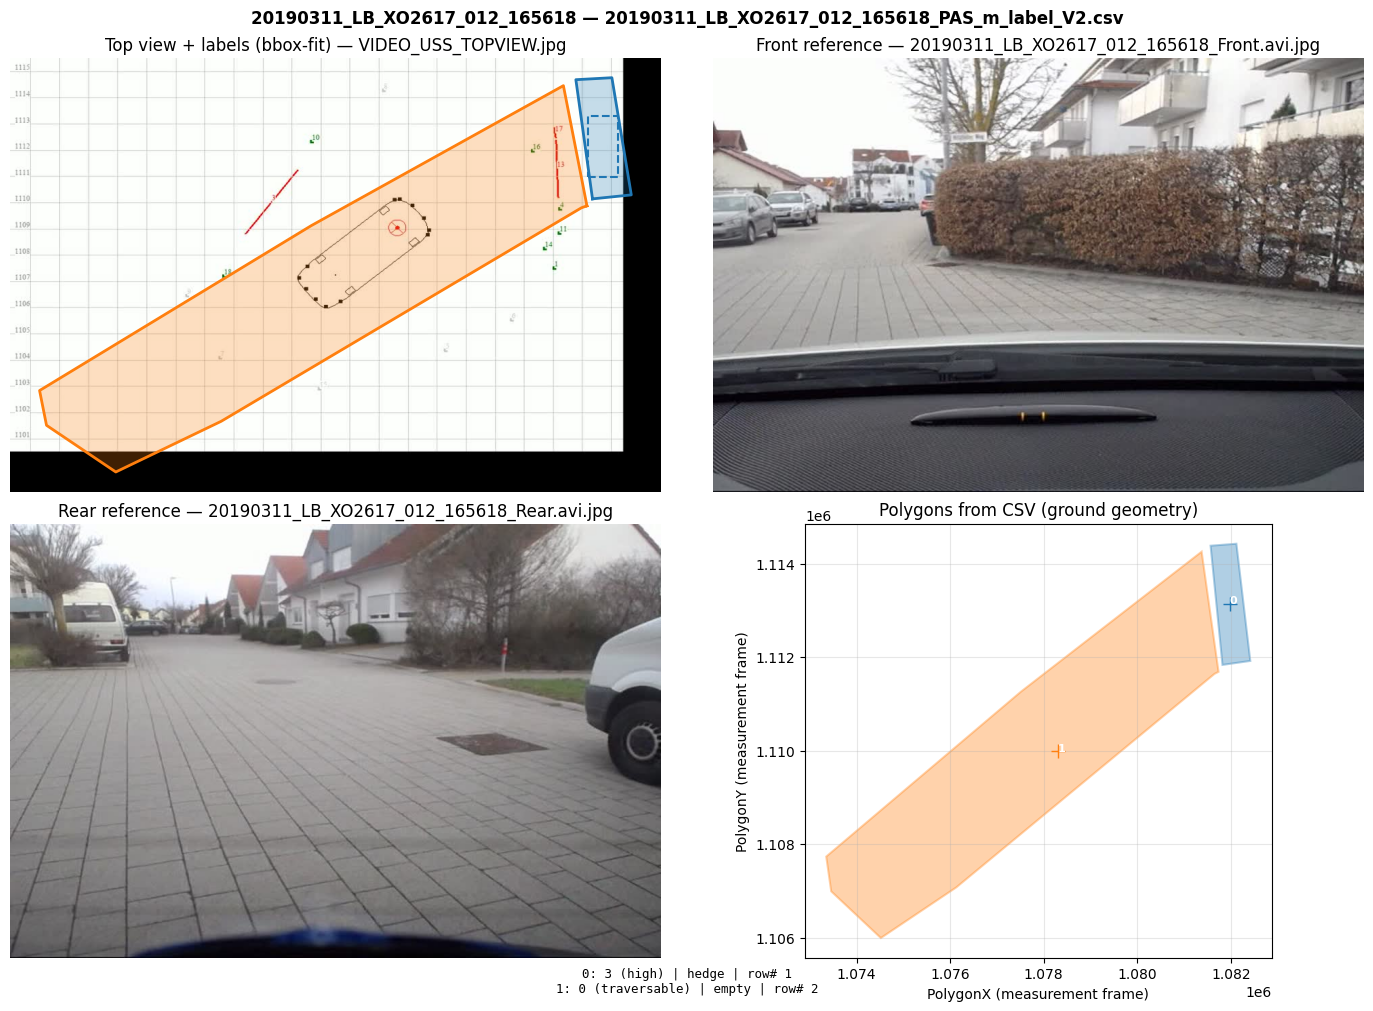

In [16]:
CLASS_NAMES = {
    "0": "traversable",
    "1": "low",
    "2": "unknown",
    "3": "high",
}


def class_display(row: dict[str, str]) -> str:
    c = class_label(row)
    name = CLASS_NAMES.get(c, "?")
    return f"{c} ({name})" if name != "?" else f"{c} (see header / data docs)"


def row_axis_aligned_box(row: dict[str, str]) -> tuple[float, float, float, float]:
    return (
        float(row["xmin"]),
        float(row["xmax"]),
        float(row["ymin"]),
        float(row["ymax"]),
    )


def world_bounds_from_rows(rows: list[dict[str, str]]) -> tuple[float, float, float, float]:
    xs: list[float] = []
    ys: list[float] = []
    for r in rows:
        px, py = parse_polygon_xy(r)
        xs.extend(px.tolist())
        ys.extend(py.tolist())
        xmin, xmax, ymin, ymax = row_axis_aligned_box(r)
        for x in (xmin, xmax):
            for y in (ymin, ymax):
                xs.append(x)
                ys.append(y)
    xs_a = np.array(xs, dtype=np.float64)
    ys_a = np.array(ys, dtype=np.float64)
    pad_x = 0.05 * (xs_a.max() - xs_a.min() + 1e-9)
    pad_y = 0.05 * (ys_a.max() - ys_a.min() + 1e-9)
    return (
        float(xs_a.min() - pad_x),
        float(xs_a.max() + pad_x),
        float(ys_a.min() - pad_y),
        float(ys_a.max() + pad_y),
    )


def world_to_pixel(
    x: np.ndarray,
    y: np.ndarray,
    w: int,
    h: int,
    xmin: float,
    xmax: float,
    ymin: float,
    ymax: float,
) -> tuple[np.ndarray, np.ndarray]:
    u = (x - xmin) / (xmax - xmin + 1e-9) * (w - 1)
    v = (1.0 - (y - ymin) / (ymax - ymin + 1e-9)) * (h - 1)
    return u, v


def draw_labels_on_ax(
    ax,
    img: np.ndarray,
    title: str,
    rows: list[dict[str, str]],
    colors: np.ndarray,
    xmin: float,
    xmax: float,
    ymin: float,
    ymax: float,
) -> None:
    h, w = img.shape[0], img.shape[1]
    ax.imshow(img)
    ax.set_title(title)
    ax.set_xlim(0, w - 1)
    ax.set_ylim(h - 1, 0)

    for i, r in enumerate(rows):
        xs, ys = parse_polygon_xy(r)
        u, v = world_to_pixel(xs, ys, w, h, xmin, xmax, ymin, ymax)
        ax.fill(u, v, color=colors[i], alpha=0.25, zorder=2)
        ax.plot(np.r_[u, u[0]], np.r_[v, v[0]], color=colors[i], linewidth=2, zorder=3)

        bx0, bx1, by0, by1 = row_axis_aligned_box(r)
        bx = np.array([bx0, bx1, bx1, bx0, bx0])
        by = np.array([by0, by0, by1, by1, by0])
        bu, bv = world_to_pixel(bx, by, w, h, xmin, xmax, ymin, ymax)
        ax.plot(bu, bv, color=colors[i], linewidth=1.5, linestyle="--", zorder=4)

    ax.axis("off")


colors = plt.cm.tab10(np.linspace(0, 1, max(10, len(rows))))
xmin, xmax, ymin, ymax = world_bounds_from_rows(rows)

fig = plt.figure(figsize=(14, 10), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.0])

ax_top = fig.add_subplot(gs[0, 0])
ax_front = fig.add_subplot(gs[0, 1])
ax_rear = fig.add_subplot(gs[1, 0])
ax_map = fig.add_subplot(gs[1, 1])

if top_view.is_file():
    img_top = mpimg.imread(top_view)
    draw_labels_on_ax(
        ax_top,
        img_top,
        f"Top view + labels (bbox-fit) — {top_view.name}",
        rows,
        colors,
        xmin,
        xmax,
        ymin,
        ymax,
    )
else:
    ax_top.axis("off")
    ax_top.text(0.5, 0.5, "Missing VIDEO_USS_TOPVIEW.jpg", ha="center", va="center", transform=ax_top.transAxes)

if front.is_file():
    ax_front.imshow(mpimg.imread(front))
    ax_front.set_title(f"Front reference — {front.name}")
else:
    ax_front.text(0.5, 0.5, "Missing Front image", ha="center", va="center", transform=ax_front.transAxes)
ax_front.axis("off")

if rear.is_file():
    ax_rear.imshow(mpimg.imread(rear))
    ax_rear.set_title(f"Rear reference — {rear.name}")
else:
    ax_rear.text(0.5, 0.5, "Missing Rear image", ha="center", va="center", transform=ax_rear.transAxes)
ax_rear.axis("off")

legend_lines = []
for i, r in enumerate(rows):
    legend_lines.append(
        f"{i}: {class_display(r)} | {r.get('Which object', '')} | row# {r.get('#', '')}"
    )
caption = "\n".join(legend_lines)
fig.text(0.5, 0.01, caption, ha="center", va="bottom", fontsize=9, family="monospace")

for i, r in enumerate(rows):
    xs, ys = parse_polygon_xy(r)
    poly = np.column_stack([xs, ys])
    patch = MplPolygon(
        poly,
        closed=True,
        fill=True,
        alpha=0.35,
        facecolor=colors[i],
        edgecolor=colors[i],
        linewidth=1.5,
    )
    ax_map.add_patch(patch)
    ax_map.plot(xs.mean(), ys.mean(), "+", color=colors[i], markersize=10)
    ax_map.annotate(str(i), (xs.mean(), ys.mean()), color="white", fontsize=8, weight="bold")

ax_map.set_aspect("equal", adjustable="box")
ax_map.set_xlabel("PolygonX (measurement frame)")
ax_map.set_ylabel("PolygonY (measurement frame)")
ax_map.set_title("Polygons from CSV (ground geometry)")
ax_map.grid(True, alpha=0.3)

fig.suptitle(f"{stem} — {label_path.name}", fontsize=12, weight="bold")
plt.show()
